Decision Tree (gini) Test Accuracy: 0.9444
Decision Tree (entropy) Test Accuracy: 0.9722
Best DT Params: {'max_depth': 3, 'min_samples_leaf': 2} | Tuned Test Acc: 1.0


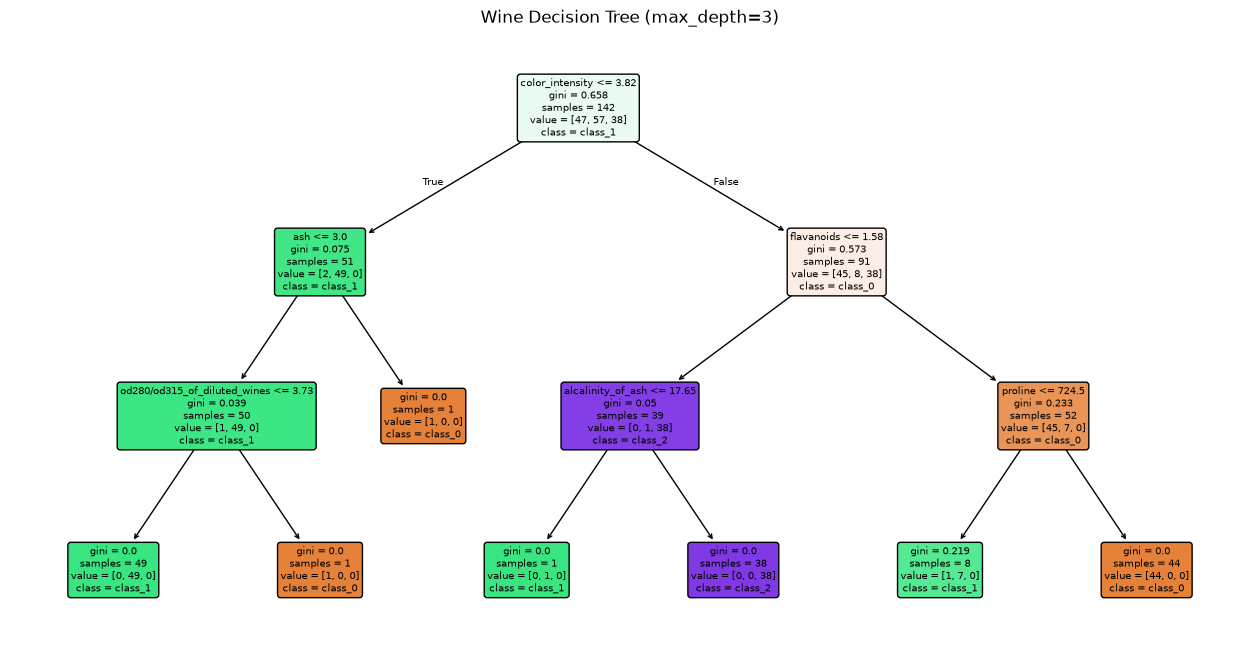


Top 5 Features (Decision Tree):
 |                              |         0 |
|:-----------------------------|----------:|
| flavanoids                   | 0.415865  |
| color_intensity              | 0.407831  |
| proline                      | 0.113104  |
| od280/od315_of_diluted_wines | 0.021387  |
| alcalinity_of_ash            | 0.0212639 |

Single Tree Acc: 0.9444 | Random Forest Acc: 1.0000 | OOB Score: 0.9789


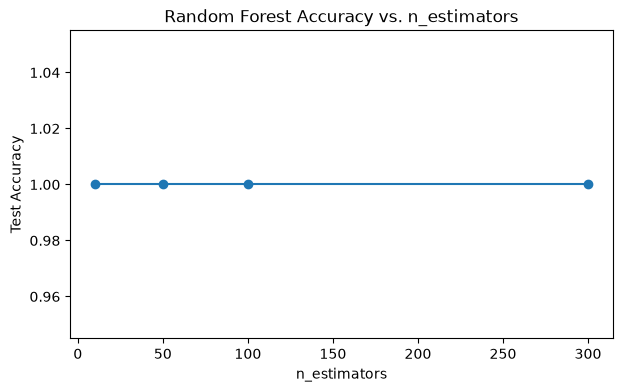

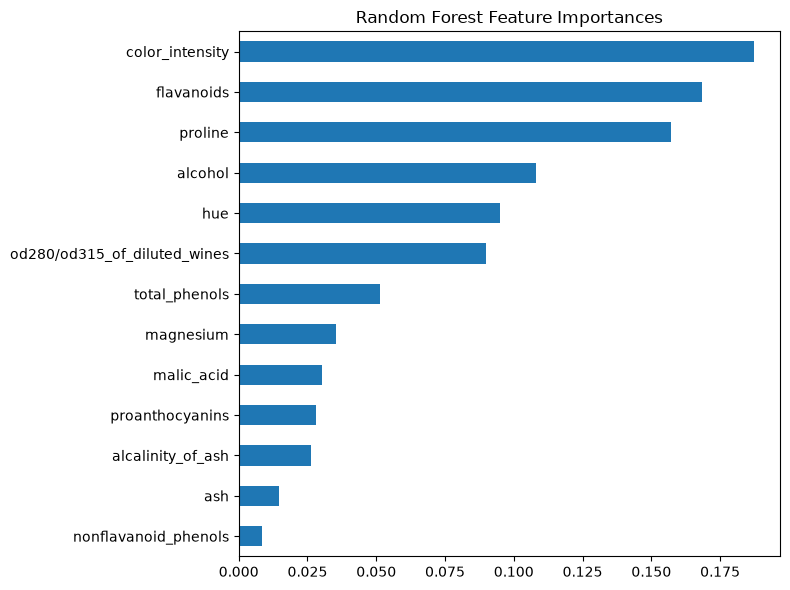

ExtraTrees Test Accuracy: 1.0000


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score

# Load & split wine dataset
wine = load_wine()
Xw, yw = wine.data, wine.target
Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.2, random_state=42, stratify=yw)

# Task 1: Gini vs Entropy
for crit in ['gini', 'entropy']:
    dt = DecisionTreeClassifier(criterion=crit, random_state=42).fit(Xw_train, yw_train)
    print(f"Decision Tree ({crit}) Test Accuracy: {accuracy_score(yw_test, dt.predict(Xw_test)):.4f}")

# Task 1: Tune max_depth and min_samples_leaf
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [2, 3, 4, 5, None], 'min_samples_leaf': [1, 2, 4, 6]},
    cv=5
).fit(Xw_train, yw_train)
print("Best DT Params:", grid.best_params_, "| Tuned Test Acc:", round(accuracy_score(yw_test, grid.predict(Xw_test)), 4))

# Task 1: Plot tree (max_depth=3) & save image
dt_vis = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xw_train, yw_train)
plt.figure(figsize=(16, 8))
plot_tree(dt_vis, feature_names=wine.feature_names, class_names=wine.target_names, filled=True, rounded=True)
plt.title("Wine Decision Tree (max_depth=3)")
plt.savefig("wine_tree.png", bbox_inches='tight')
plt.show()

# Task 1: Top 5 features
dt_imp = pd.Series(dt_vis.feature_importances_, index=wine.feature_names).sort_values(ascending=False)
print("\nTop 5 Features (Decision Tree):\n", dt_imp.head(5).to_markdown())

# Task 2: Random Forest with OOB Score
rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=42).fit(Xw_train, yw_train)
print(f"\nSingle Tree Acc: {accuracy_score(yw_test, dt_vis.predict(Xw_test)):.4f} | "
      f"Random Forest Acc: {accuracy_score(yw_test, rf.predict(Xw_test)):.4f} | "
      f"OOB Score: {rf.oob_score_:.4f}")

# Task 2: Vary n_estimators [10, 50, 100, 300]
est_list = [10, 50, 100, 300]
est_accs = [accuracy_score(yw_test, RandomForestClassifier(n_estimators=n, random_state=42).fit(Xw_train, yw_train).predict(Xw_test)) for n in est_list]
plt.figure(figsize=(7, 4))
plt.plot(est_list, est_accs, marker='o')
plt.xlabel("n_estimators")
plt.ylabel("Test Accuracy")
plt.title("Random Forest Accuracy vs. n_estimators")
plt.show()

# Task 2: Feature importances bar chart
pd.Series(rf.feature_importances_, index=wine.feature_names).sort_values().plot(kind='barh', figsize=(8, 6), title="Random Forest Feature Importances")
plt.tight_layout()
plt.show()

# Bonus: ExtraTreesClassifier comparison
et = ExtraTreesClassifier(n_estimators=200, random_state=42).fit(Xw_train, yw_train)
print(f"ExtraTrees Test Accuracy: {accuracy_score(yw_test, et.predict(Xw_test)):.4f}")

When plot_tree draws the flowchart of your Decision Tree, it asks a series of True/False questions starting from the top box

Question 1 (Root Split): "Is the wine's proline level ≤ 755.0?" If False (> 755), it goes right and is almost certainly Class 0. If True (<= 755), it goes left to be separated further.   


Question 2 (Second Split): For those remaining wines on the left, it asks "Is od280/od315_of_diluted_wines ≤ 2.115?" If True, it classifies them as Class 2; if False, it classifies them as Class 1.   


Gini Impurity (3 Lines):
Think of a bucket of colored marbles (the classes):   


Gini = 0.0 means all marbles in the bucket are the exact same color (100% pure).   


Higher Gini (up to ~0.67 for 3 classes) means the bucket is heavily mixed with different colors.   

The tree tests different split rules and picks whichever question creates the purest buckets (lowest Gini score).   



Bootstrap Aggregation (Bagging) & Why Random Forest Overfits Less:

A single Decision Tree is like one student who memorizes every specific practice question—if you give them slightly new test data, they make mistakes (overfitting).   


Bagging (Random Forest) creates 200 different trees, giving each tree a slightly different random sample of the training rows (drawn with replacement) and random subsets of features.   


Because every tree sees slightly different data, their individual errors cancel out when all 200 trees take a majority vote, giving much higher accuracy on unseen test data.   
